# Model Comparison

This notebook trains and evaluates three binary classification models
for heart disease prediction: Logistic Regression, Random Forest, and
a Multi-Layer Perceptron (MLP).

The main objective is to maximize a weighted score combining recall
and precision, with a greater weight assigned to recall.

In [ ]:
# Standard library
import sys
import random
import copy

sys.path.append("..")

# Third-party libraries
import numpy as np
import sklearn
import matplotlib.pyplot as plt

import torch
from torch import nn, cuda
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Project modules
from src.data_cleaning import load_data
from src.models import (
    create_logistic_regression,
    create_random_forest_search,
    MLP
)
from src.evaluation import (
    evaluate_model,
    select_threshold,
    plot_confusion_matrix,
    plot_precision_recall_curve,
    compare_models,
    plot_precision_recall_comparison
)

In [ ]:
RECALL_WEIGHT = 0.8

## Data Preparation

Set random seeds to ensure reproducibility.

Load the cleaned dataset and split it into training (70%), validation (15%), and test (15%) sets using stratified sampling.

Standardize the input features using a `StandardScaler` fitted exclusively on the training set to avoid data leakage.

In [ ]:
RANDOM_STATE = 40

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

X, y = load_data()

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=RANDOM_STATE, stratify=y_temp)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

## Logistic Regression

Train a Logistic Regression model using cross-validation to select
the regularization strength. Recall is used as the scoring metric
during cross-validation.

In [ ]:
model_reg = create_logistic_regression(RANDOM_STATE)

model_reg.fit(X_train, y_train)

print(f"Maximum number of iterations: {model_reg.n_iter_.max()}")

Maximum number of iterations: 8


### Threshold Selection

Use the validation set to select the decision threshold that maximizes
a weighted score combining recall and precision, with greater weight
assigned to recall.

In [ ]:
y_proba_val_logreg = model_reg.predict_proba(X_val)[:, 1]

threshold_logreg, val_metrics_logreg = select_threshold(
    y_val,
    y_proba_val_logreg,
    recall_weight=RECALL_WEIGHT
)

print(f"Selected threshold: {threshold_logreg:.4f}")
print(f"Validation precision: {val_metrics_logreg['precision']:.4f}")
print(f"Validation recall: {val_metrics_logreg['recall']:.4f}")
print(f"Validation score: {val_metrics_logreg['score']:.4f}")

Selected threshold: 0.1518
Validation precision: 0.6364
Validation recall: 1.0000
Validation score: 0.9273


### Test Evaluation

Apply the selected threshold to the test set and compute the evaluation
metrics. The test set is kept separate from model and threshold selection.

In [ ]:
y_proba_logreg_all = model_reg.predict_proba(X_test)
y_proba_logreg = y_proba_logreg_all[:, 1]

y_pred_logreg = (y_proba_logreg >= threshold_logreg).astype(int)

loss_logreg = sklearn.metrics.log_loss(
    y_test,
    y_proba_logreg_all
)
print(f"Test loss: {loss_logreg:.4f}")

logreg_metrics = evaluate_model(
    y_test,
    y_pred_logreg,
    y_proba_logreg,
    loss=loss_logreg,
    threshold=threshold_logreg
)

Test loss: 0.3155


### Performance Visualization

Visualize the confusion matrix and precision-recall curve to examine
the model's classification errors and precision-recall trade-off.

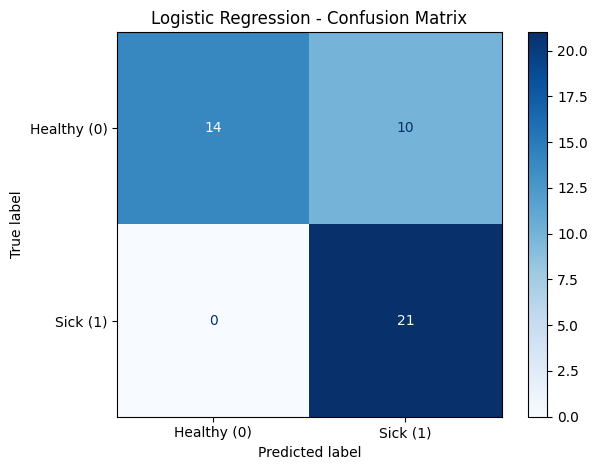

In [ ]:
plot_confusion_matrix(
    y_test,
    y_pred_logreg,
    "Logistic Regression"
)

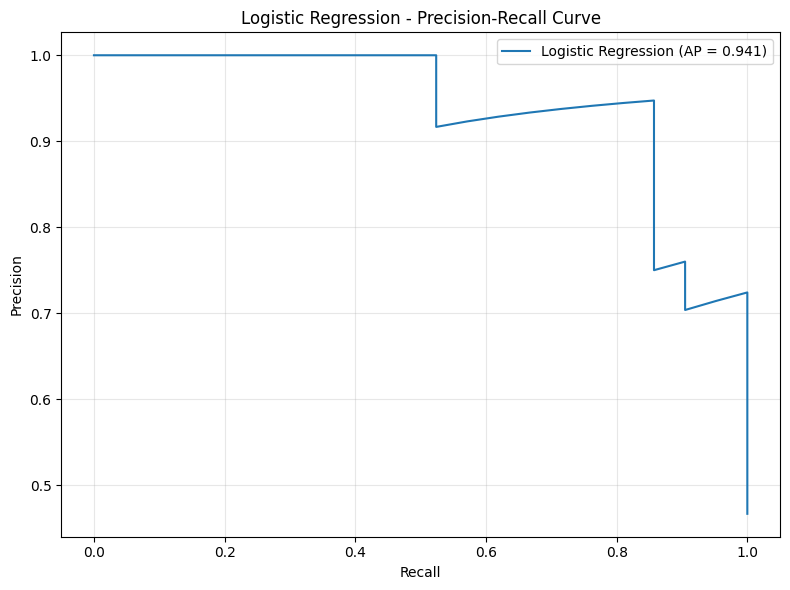

In [ ]:
logreg_curve = plot_precision_recall_curve(
    y_test,
    y_proba_logreg,
    "Logistic Regression"
)

## Random Forest

Use grid search with cross-validation to select the Random Forest
hyperparameters, with recall as the scoring metric.

In [ ]:
grid = create_random_forest_search(RANDOM_STATE)

grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_)
print("")

best_model = grid.best_estimator_

{'max_depth': 7, 'min_samples_split': 7, 'n_estimators': 50}
0.8315789473684211



### Threshold Selection

Use the validation set to select the decision threshold that maximizes
a weighted score combining recall and precision, with greater weight
assigned to recall.

In [ ]:
y_proba_val_rf = best_model.predict_proba(X_val)[:, 1]

threshold_rf, val_metrics_rf = select_threshold(
    y_val,
    y_proba_val_rf,
    recall_weight=RECALL_WEIGHT
)

print(f"Selected threshold: {threshold_rf:.4f}")
print(f"Validation precision: {val_metrics_rf['precision']:.4f}")
print(f"Validation recall: {val_metrics_rf['recall']:.4f}")
print(f"Validation score: {val_metrics_rf['score']:.4f}")

Selected threshold: 0.1379
Validation precision: 0.5833
Validation recall: 1.0000
Validation score: 0.9167


### Test Evaluation

Evaluate the selected Random Forest model on the test set using the
threshold determined from the validation set.

In [ ]:
y_proba_rf_all = best_model.predict_proba(X_test)
y_proba_rf = y_proba_rf_all[:, 1]

y_pred_rf = (y_proba_rf >= threshold_rf).astype(int)

loss_rf = sklearn.metrics.log_loss(y_test, y_proba_rf_all)
print(f"Test loss: {loss_rf:.4f}")

rf_metrics = evaluate_model(
    y_test,
    y_pred_rf,
    y_proba_rf,
    loss=loss_rf,
    threshold=threshold_rf
)

Test loss: 0.3702


### Performance Visualization

Visualize the confusion matrix and precision-recall curve to examine
the model's classification errors and precision-recall trade-off.

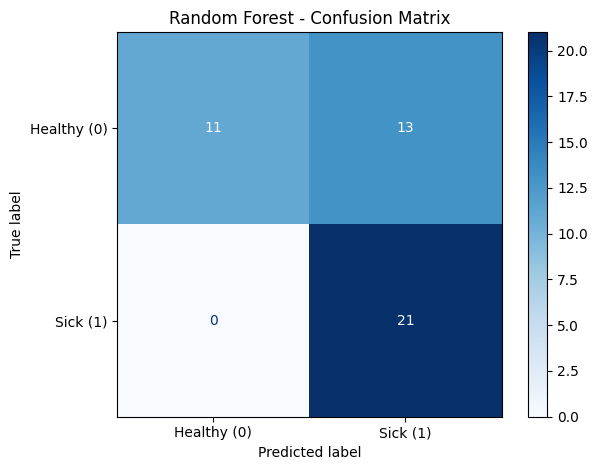

In [ ]:
plot_confusion_matrix(
    y_test,
    y_pred_rf,
    "Random Forest"
)

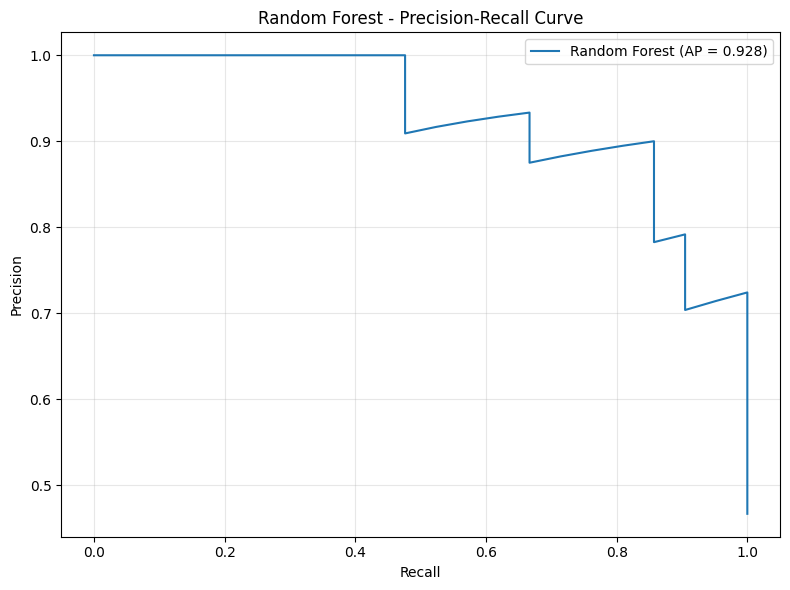

In [ ]:
rf_curve = plot_precision_recall_curve(
    y_test,
    y_proba_rf,
    "Random Forest"
)

## Multi-Layer Perceptron (MLP)

Define the training hyperparameters and select the available computing
device (GPU or CPU).

In [ ]:
BATCH_SIZE = 16
DROPOUT = 0.4
LEARNING_RATE = 5e-5
WEIGHT_DECAY = 1e-2
EPOCHS = 1500


device = "cuda" if cuda.is_available() else "cpu"
print(f"Current device: {device}")

Current device: cpu


### Data Preparation

Convert the datasets into PyTorch tensors and create a DataLoader
to process the training data in mini-batches.

In [ ]:
Xt_train = torch.tensor(X_train, dtype=torch.float32, device=device)
yt_train = torch.tensor(y_train.to_numpy(), dtype=torch.long, device=device)

Xt_val = torch.tensor(X_val, dtype=torch.float32, device=device)
yt_val = torch.tensor(y_val.to_numpy(), dtype=torch.long, device=device)

Xt_test = torch.tensor(X_test, dtype=torch.float32, device=device)
yt_test = torch.tensor(y_test.to_numpy(), dtype=torch.long, device=device)


in_features = Xt_train.shape[1]
out_features = len(torch.unique(yt_train))

train_dataset = TensorDataset(Xt_train, yt_train)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

### Model Configuration

Initialize the MLP, Adam optimizer, learning rate scheduler, and
cross-entropy loss function.

In [ ]:
mlp_model = MLP(in_features, out_features, DROPOUT).to(device)
optimizer = torch.optim.Adam(
    params=mlp_model.parameters(), 
    lr=LEARNING_RATE, 
    weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=20
)
criterion = nn.CrossEntropyLoss()

### Training

Train the MLP over multiple epochs. Track training and validation loss,
reduce the learning rate when validation loss plateaus, and save the
model weights that achieve the lowest validation loss.

In [ ]:
train_losses = []
val_losses = []

best_val_loss = float("inf")
best_weights = None
best_epoch = 0

for epoch in range(1, EPOCHS + 1):

    mlp_model.train()
    mean_train_loss = 0

    for Xt_batch, yt_batch in train_loader:

        yt_pred = mlp_model(Xt_batch)

        train_loss = criterion(yt_pred, yt_batch)
        mean_train_loss += (
            train_loss.item()
            * Xt_batch.shape[0]
            / len(train_loader.dataset)
        )

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

    mlp_model.eval()

    with torch.no_grad():
        yt_pred = mlp_model(Xt_val)
        val_loss = criterion(yt_pred, yt_val).item()
        scheduler.step(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(mlp_model.state_dict())
            best_epoch = epoch

    if epoch % 100 == 0:
        train_losses.append(mean_train_loss)
        val_losses.append(val_loss)

        print(f"Epoch: {epoch}")
        print(f"Train loss: {mean_train_loss:.4f}")
        print(f"Val loss: {val_loss:.4f}")
        print(f"Learning rate: {optimizer.param_groups[0]['lr']:.6f}")
        print("")

mlp_model.load_state_dict(best_weights)

print("")
print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")

Epoch: 100
Train loss: 0.6120
Val loss: 0.5855
Learning rate: 0.000050

Epoch: 200
Train loss: 0.5379
Val loss: 0.4548
Learning rate: 0.000050

Epoch: 300
Train loss: 0.4472
Val loss: 0.3652
Learning rate: 0.000050

Epoch: 400
Train loss: 0.4515
Val loss: 0.3326
Learning rate: 0.000050

Epoch: 500
Train loss: 0.3891
Val loss: 0.3198
Learning rate: 0.000050

Epoch: 600
Train loss: 0.3768
Val loss: 0.3152
Learning rate: 0.000050

Epoch: 700
Train loss: 0.3646
Val loss: 0.3129
Learning rate: 0.000025

Epoch: 800
Train loss: 0.3710
Val loss: 0.3128
Learning rate: 0.000002

Epoch: 900
Train loss: 0.3926
Val loss: 0.3128
Learning rate: 0.000000

Epoch: 1000
Train loss: 0.3412
Val loss: 0.3128
Learning rate: 0.000000

Epoch: 1100
Train loss: 0.3784
Val loss: 0.3128
Learning rate: 0.000000

Epoch: 1200
Train loss: 0.3790
Val loss: 0.3128
Learning rate: 0.000000

Epoch: 1300
Train loss: 0.3699
Val loss: 0.3128
Learning rate: 0.000000

Epoch: 1400
Train loss: 0.3614
Val loss: 0.3128
Learning rat

### Training and Validation Loss

Plot the training and validation losses to examine the model's
learning behavior over the course of training.

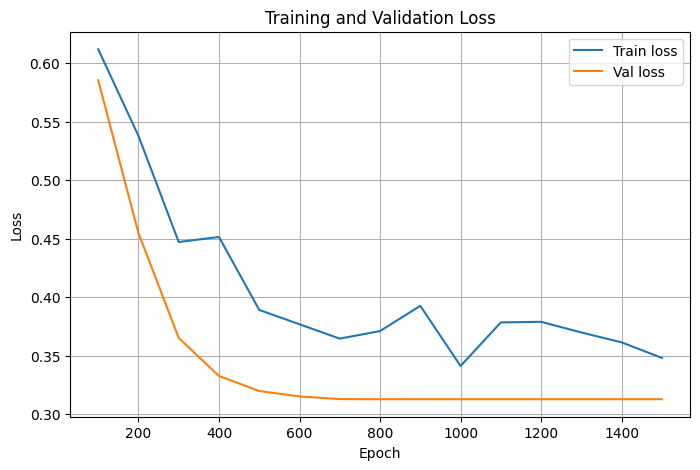

In [ ]:
epochs = range(100, EPOCHS + 1, 100)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, label="Train loss")
plt.plot(epochs, val_losses, label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

### Threshold Selection

Use validation predictions to select the decision threshold that
maximizes a weighted score combining recall and precision, with
greater weight assigned to recall.

In [ ]:
mlp_model.eval()

with torch.no_grad():
    yt_pred_val = mlp_model(Xt_val)
    y_proba_val_mlp = torch.softmax(
        yt_pred_val, dim=1
    )[:, 1].cpu().numpy()

y_true_val_mlp = yt_val.cpu().numpy()

threshold_mlp, val_metrics_mlp = select_threshold(
    y_true_val_mlp,
    y_proba_val_mlp,
    recall_weight=RECALL_WEIGHT
)

print(f"Selected threshold: {threshold_mlp:.4f}")
print(f"Validation precision: {val_metrics_mlp['precision']:.4f}")
print(f"Validation recall: {val_metrics_mlp['recall']:.4f}")
print(f"Validation score: {val_metrics_mlp['score']:.4f}")

Selected threshold: 0.2057
Validation precision: 0.7241
Validation recall: 1.0000
Validation score: 0.9448


### Test Evaluation

Evaluate the selected MLP checkpoint on the test set using the
threshold determined from the validation set.

In [ ]:
mlp_model.eval()

with torch.no_grad():
    yt_pred = mlp_model(Xt_test)
    mlp_loss = criterion(yt_pred, yt_test).item()

    y_true_mlp = yt_test.cpu().numpy()
    y_proba_mlp = torch.softmax(
        yt_pred, dim=1
    )[:, 1].cpu().numpy()

    y_pred_mlp = (
        y_proba_mlp >= threshold_mlp
    ).astype(int)

print(f"Test loss: {mlp_loss:.4f}")

mlp_metrics = evaluate_model(
    y_true_mlp,
    y_pred_mlp,
    y_proba_mlp,
    loss=mlp_loss,
    threshold=threshold_mlp
)

Test loss: 0.3432


### Performance Visualization

Visualize the confusion matrix and precision-recall curve to examine
the model's classification errors and precision-recall trade-off.

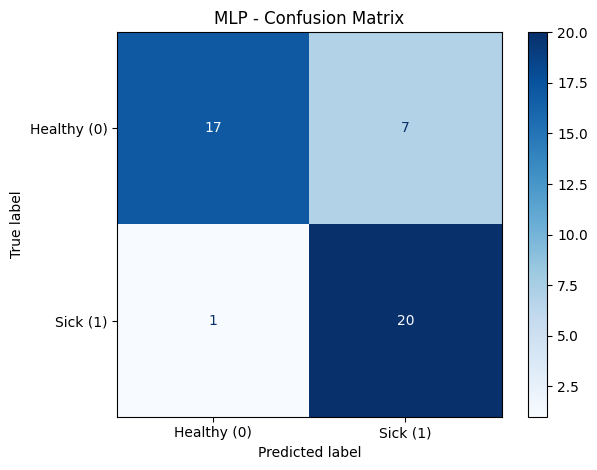

In [ ]:
plot_confusion_matrix(
    y_true_mlp,
    y_pred_mlp,
    "MLP"
)

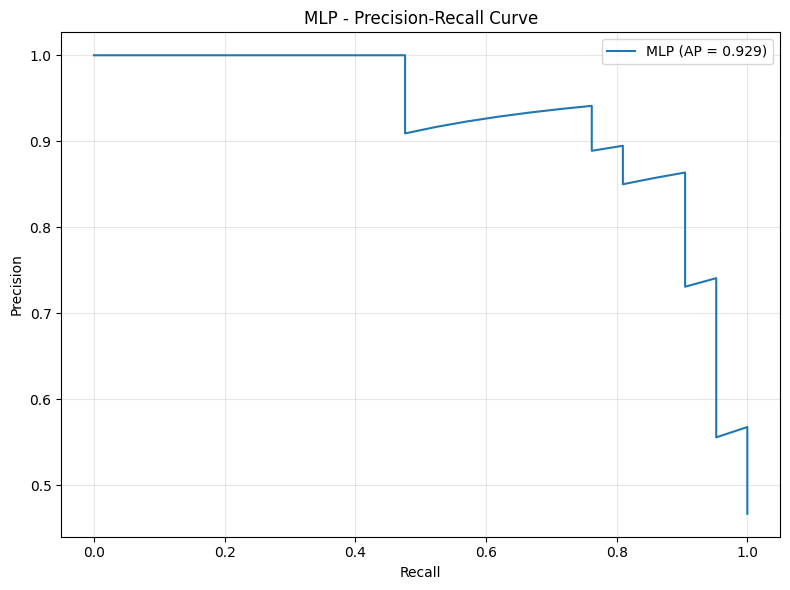

In [ ]:
mlp_curve = plot_precision_recall_curve(
    y_true_mlp,
    y_proba_mlp,
    "MLP"
)

## Model Comparison

Compare the three models using their test-set metrics, including
accuracy, precision, recall, F1-score, log loss, and Average Precision.

In [ ]:
model_metrics = {
    "Logistic Regression": logreg_metrics,
    "Random Forest": rf_metrics,
    "MLP": mlp_metrics
}

results = compare_models(model_metrics)
display(results.round(4))

,Threshold,Loss,Accuracy,Precision,Recall,F1-score,Average Precision
Model,,,,,,,
Logistic Regression,0.1518,0.3155,0.7778,0.6774,1.0000,0.8077,0.9407
Random Forest,0.1379,0.3702,0.7111,0.6176,1.0000,0.7636,0.9285
MLP,0.2057,0.3432,0.8222,0.7407,0.9524,0.8333,0.9288


#### Results Analysis

Logistic Regression and Random Forest both achieve a recall of 1.0, meaning that no positive cases are missed on this test set. However, Logistic Regression achieves higher precision, accuracy, and F1-score than Random Forest.

The MLP achieves the highest accuracy, precision, and F1-score, but its recall is lower (0.9524). Logistic Regression achieves the highest Average Precision, making it a strong candidate given the objective of maximizing a weighted score combining recall and precision, with greater weight assigned to recall.

Given the priority placed on recall, Logistic Regression appears to be the most suitable model among the three. However, these results are based on a single train-validation-test split and may not generalize to unseen data. A robustness analysis is therefore conducted using stratified five-fold cross-validation with a fixed random seed (`40`) to assess how consistently the models perform across different data splits.

### Precision-Recall Curve Comparison

Compare the precision-recall curves to examine how precision varies
with recall across the three models, independently of the selected
decision thresholds.

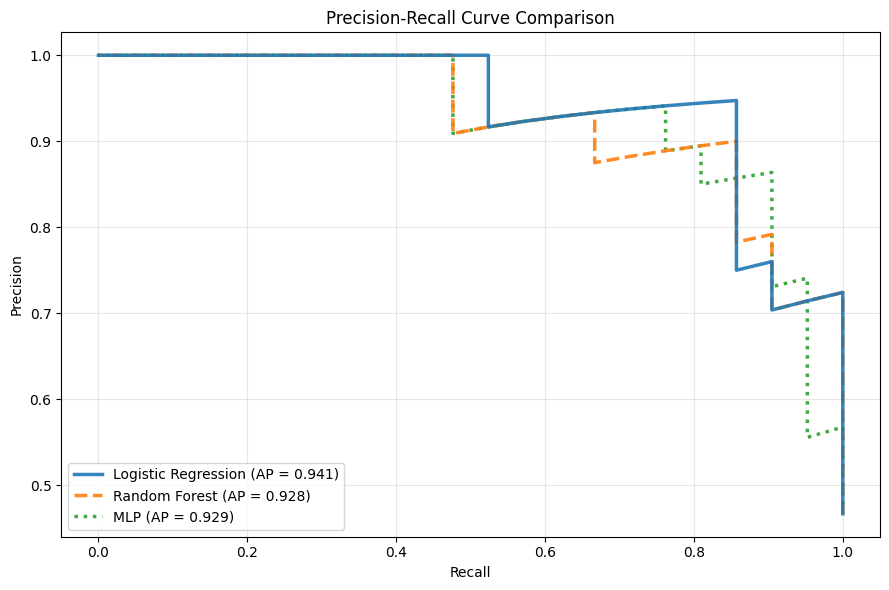

In [ ]:
curves = {
    "Logistic Regression": logreg_curve,
    "Random Forest": rf_curve,
    "MLP": mlp_curve
}

plot_precision_recall_comparison(curves)

#### Precision-Recall Analysis

The three models achieve similar Average Precision scores, suggesting comparable overall performance across different decision thresholds.

The precision-recall curves provide a more complete comparison by showing how precision varies at different recall levels. At the recall selected for the MLP (0.9524), Logistic Regression achieves lower precision, illustrating the trade-off between detecting more positive cases and limiting false positives.